# **Lab 9 - Morphological Operations: Assignment**

**Objective:** Apply morphological operations (erosion, dilation, opening, closing) to a new binary image (**Balls**) and investigate how the shape and size of the structuring element affect the result.

> The Balls image is embedded inside this notebook: if `Balls_1_.png` is not in the folder, the notebook creates it automatically, so it runs anywhere.

In [1]:
# Embedded copy of the Balls image (used only if Balls_1_.png is not found in the folder)
BALLS_B64 = "..."

'Balls_1_.png' was not found -> created it from the embedded copy.
Image size: (1234, 1274)
Foreground (white) pixels: 500374
Connected foreground objects: 23


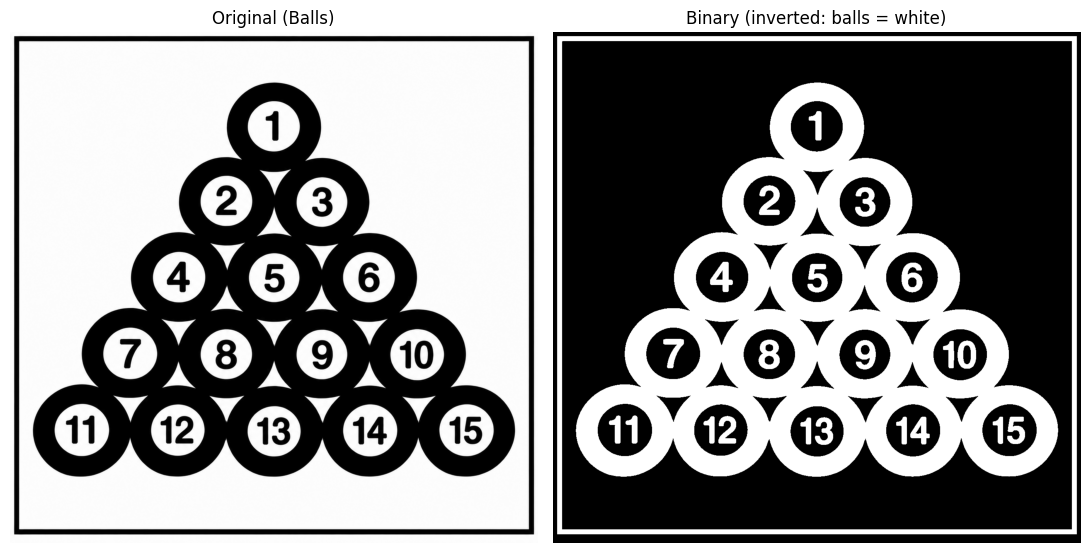

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import base64

imgFile = 'Balls_1_.png'
if not os.path.exists(imgFile):
    # image not uploaded -> recreate it from the embedded copy
    with open(imgFile, 'wb') as f:
        f.write(base64.b64decode(BALLS_B64))
    print(f"'{imgFile}' was not found -> created it from the embedded copy.")

# 1. Load image in grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize with Otsu.  Morphology treats WHITE pixels as the foreground (object),
#    but in this picture the balls are BLACK on a white background,
#    so we use THRESH_BINARY_INV to make the balls (and numbers) white.
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

def n_components(x):
    # number of connected white objects (the background label is not counted)
    return cv2.connectedComponents(x)[0] - 1

print("Image size:", binary.shape)
print("Foreground (white) pixels:", int(np.count_nonzero(binary)))
print("Connected foreground objects:", n_components(binary))

plt.figure(figsize=(11, 5.5))
plt.subplot(1, 2, 1), plt.imshow(img, 'gray'),    plt.title('Original (Balls)'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary, 'gray'), plt.title('Binary (inverted: balls = white)'), plt.axis('off')
plt.tight_layout()
plt.show()

# Task 1: Apply Morphological Operations to a New Image

A **15 x 15 square** structuring element is used because the image is large (about 1270 x 1230 pixels); a 3x3 element would change the picture by only one pixel. 

| Operation | Definition | Expected effect |
|---|---|---|
| Erosion | min under the kernel | shrinks objects, removes thin parts, can split touching objects |
| Dilation | max under the kernel | grows objects, fills small holes/gaps, can join objects |
| Opening | erosion -> dilation | removes small/thin objects, keeps the size of big shapes |
| Closing | dilation -> erosion | fills small holes and gaps, keeps the size of big shapes |

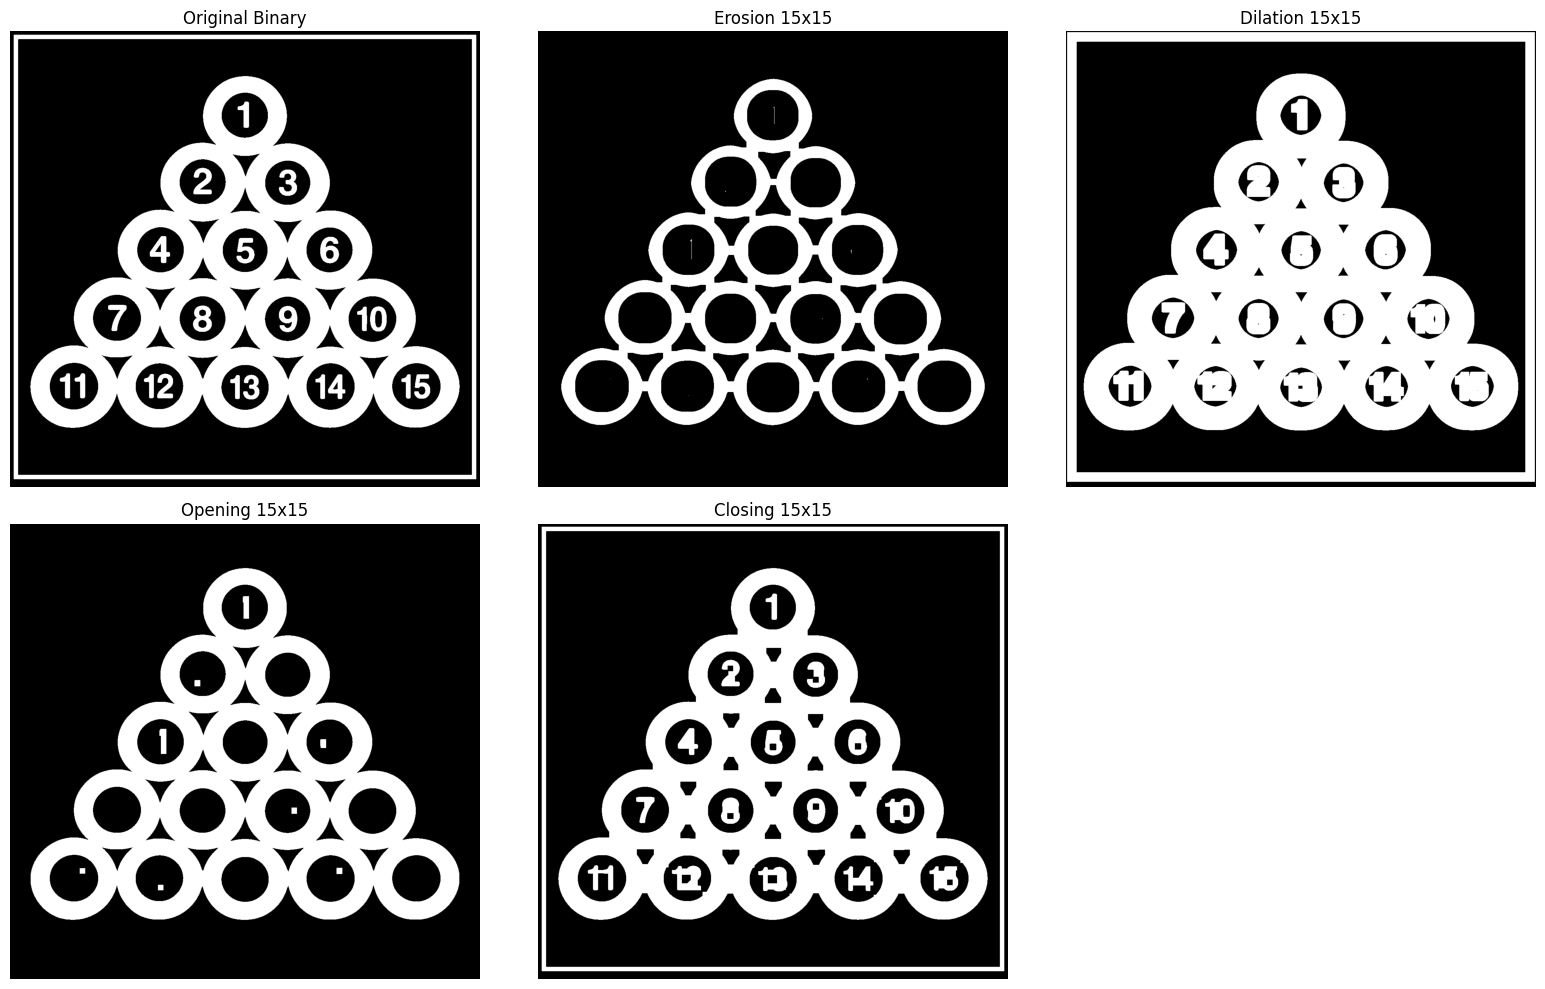

Image               White pixels    Change vs original   Objects
Original Binary          500,374                  0.0%        23
Erosion 15x15            278,086                -44.4%         9
Dilation 15x15           721,008                 44.1%        10
Opening 15x15            412,388                -17.6%         9
Closing 15x15            515,973                  3.1%        17


In [3]:
kernel = np.ones((15, 15), np.uint8)

eroded  = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

results = [('Original Binary', binary), ('Erosion 15x15', eroded), ('Dilation 15x15', dilated),
           ('Opening 15x15', opening), ('Closing 15x15', closing)]

plt.figure(figsize=(16, 10))
for i, (title, im) in enumerate(results):
    plt.subplot(2, 3, i + 1), plt.imshow(im, 'gray'), plt.title(title), plt.axis('off')
plt.tight_layout()
plt.show()

print(f"{'Image':18s}{'White pixels':>14s}{'Change vs original':>22s}{'Objects':>10s}")
base = np.count_nonzero(binary)
for title, im in results:
    n = np.count_nonzero(im)
    print(f"{title:18s}{n:14,d}{(n - base) / base * 100:21.1f}%{n_components(im):10d}")

### Observations (Task 1)

In the binary image the **white** pixels are the foreground: the ball rings, the numbers and the thin outer frame. The black discs inside the rings are holes.

* **Erosion** makes every ring thinner (white pixels drop by 44%) and the holes inside the rings bigger. The thin parts disappear completely: the numbers and the outer frame are gone (the number of objects falls from 23 to 9). The rings only touch each other at small points, which also become narrower.
* **Dilation** makes the rings thicker (+44% white pixels): the holes shrink, the numbers become fat blobs that start to fill the holes, the gaps between the balls are nearly closed so the balls merge into one big shape, and the frame becomes thicker.
* **Opening** (erosion then dilation) removes the objects that are thinner than the 15x15 kernel: the numbers and the thin frame are removed (only tiny dots of the digits remain), while the big rings keep almost their original size and shape (-17.6%).
* **Closing** (dilation then erosion) fills small gaps and holes: the narrow spaces between the balls get smaller and the numbers become thick, merged blobs, but the rings and the frame keep their original size (+3.1%).

# Task 2: Experiment with Structuring Elements

Erosion and dilation are repeated with three kernel **shapes** (square, cross, ellipse) and three **sizes** (3x3, 5x5, 7x7).

* `cv2.MORPH_RECT` - square
* `cv2.MORPH_CROSS` - cross (plus sign)
* `cv2.MORPH_ELLIPSE` - ellipse / disc

The kernels themselves:

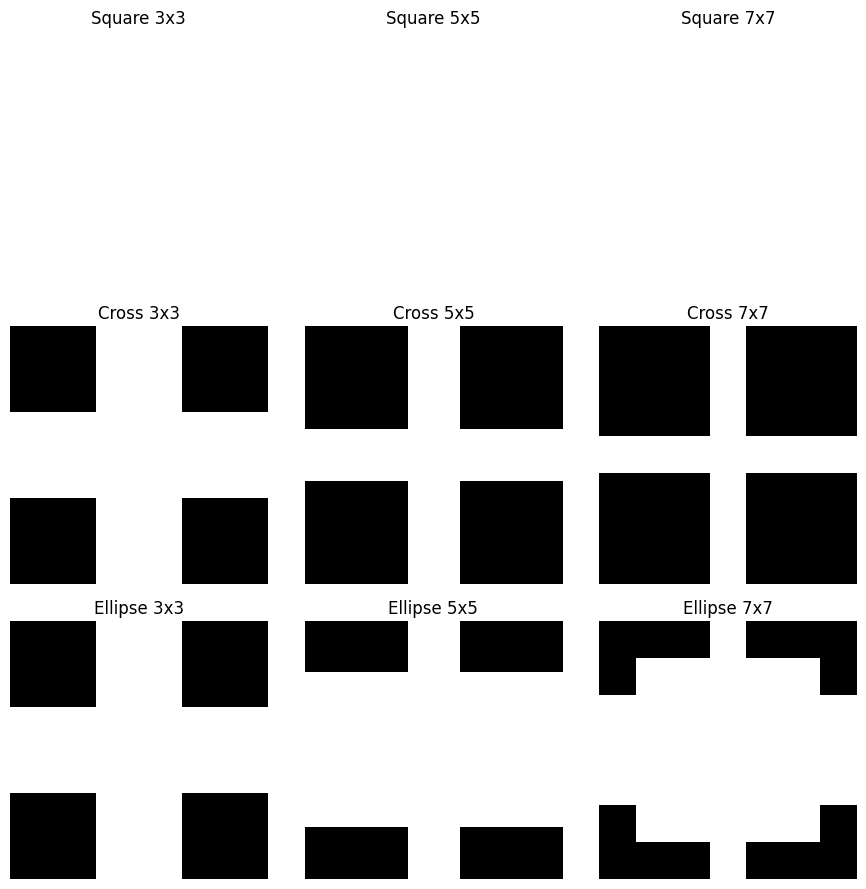

5x5 Cross:
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
5x5 Ellipse:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


In [4]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

# Show the 9 structuring elements
plt.figure(figsize=(9, 9))
for r, (sname, s) in enumerate(shapes.items()):
    for c, k in enumerate(sizes):
        se = cv2.getStructuringElement(s, (k, k))
        plt.subplot(3, 3, r * 3 + c + 1), plt.imshow(se, 'gray', vmin=0, vmax=1)
        plt.title(f'{sname} {k}x{k}'), plt.axis('off')
plt.tight_layout()
plt.show()

print("5x5 Cross:\n", cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5)))
print("5x5 Ellipse:\n", cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

### Erosion with different shapes and sizes

Because the differences between 3x3, 5x5 and 7x7 are only a few pixels wide, the plots below are **zoomed on a small region** (the balls 9 and 10 and their numbers). Rows = shape, columns = size.

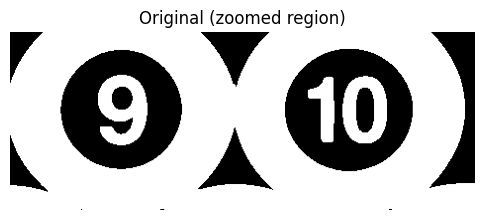

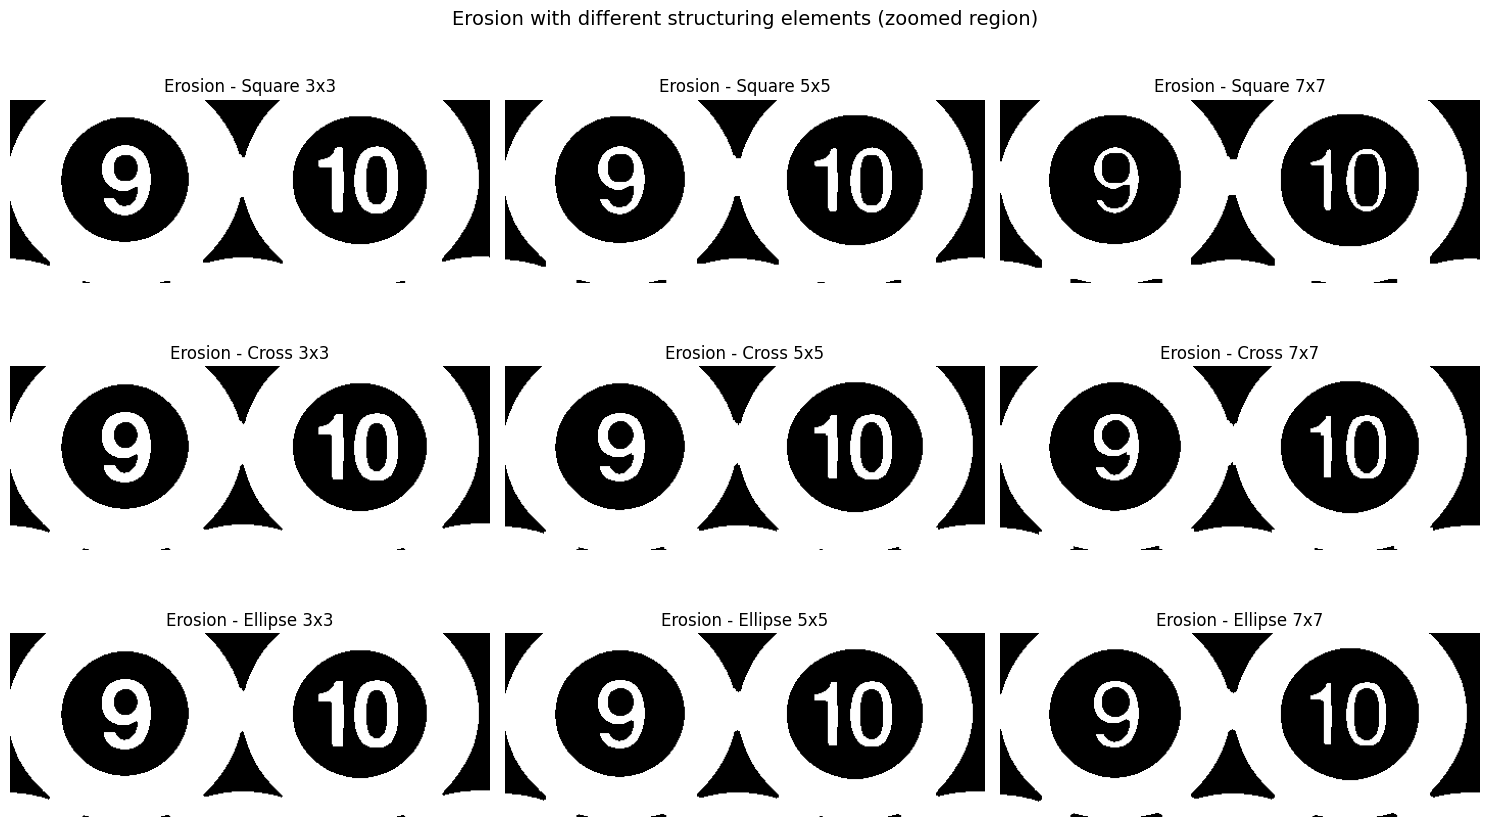

In [5]:
# Region of interest (zoom) so that the small differences become visible
y0, y1, x0, x1 = 700, 880, 640, 1110
roi = lambda im: im[y0:y1, x0:x1]

def run_grid(op_name, op):
    plt.figure(figsize=(15, 9))
    for r, (sname, s) in enumerate(shapes.items()):
        for c, k in enumerate(sizes):
            se = cv2.getStructuringElement(s, (k, k))
            out = op(binary, se)
            plt.subplot(3, 3, r * 3 + c + 1)
            plt.imshow(roi(out), 'gray')
            plt.title(f'{op_name} - {sname} {k}x{k}'), plt.axis('off')
    plt.suptitle(f'{op_name} with different structuring elements (zoomed region)', fontsize=14)
    plt.tight_layout()
    plt.show()

erode_fn  = lambda im, se: cv2.erode(im, se)
dilate_fn = lambda im, se: cv2.dilate(im, se)

plt.figure(figsize=(6, 3))
plt.imshow(roi(binary), 'gray'), plt.title('Original (zoomed region)'), plt.axis('off')
plt.show()

run_grid('Erosion', erode_fn)

### Dilation with different shapes and sizes

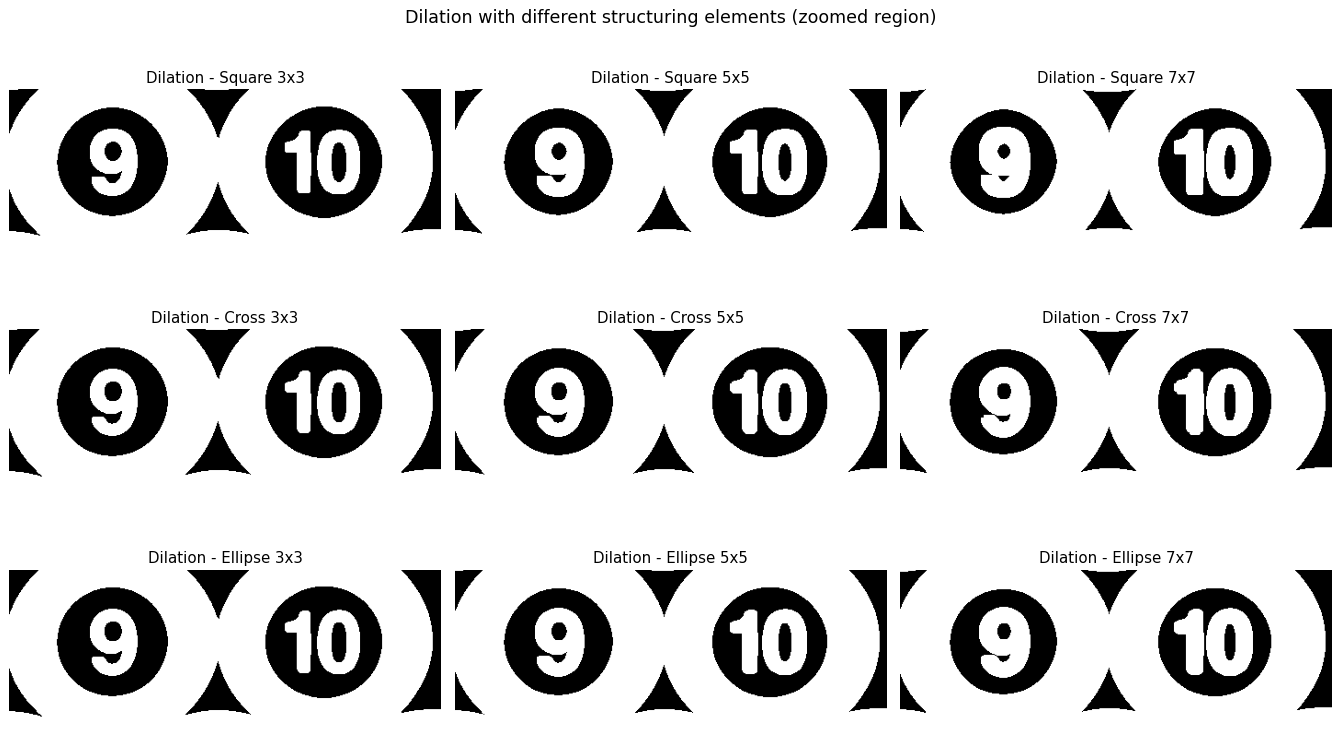

In [6]:
run_grid('Dilation', dilate_fn)

### Quantitative comparison (whole image)

Number of white (foreground) pixels after each operation, and the number of connected objects. The original image has the values printed at the top.

Original: 500,374 white pixels, 23 objects

=== EROSION ===
Shape       Size   White pixels    Change  Objects
Square       3x3        466,395     -6.8%       23
Square       5x5        432,293    -13.6%       23
Square       7x7        398,085    -20.4%       23
Cross        3x3        473,108     -5.4%       23
Cross        5x5        445,935    -10.9%       23
Cross        7x7        418,852    -16.3%       23
Ellipse      3x3        473,108     -5.4%       23
Ellipse      5x5        440,791    -11.9%       23
Ellipse      7x7        413,345    -17.4%       23

=== DILATION ===
Shape       Size   White pixels    Change  Objects
Square       3x3        534,094      6.7%       23
Square       5x5        567,126     13.3%       23
Square       7x7        599,496     19.8%       23
Cross        3x3        527,560      5.4%       23
Cross        5x5        554,380     10.8%       23
Cross        7x7        580,813     16.1%       23
Ellipse      3x3        527,560      5.4%       23
Elli

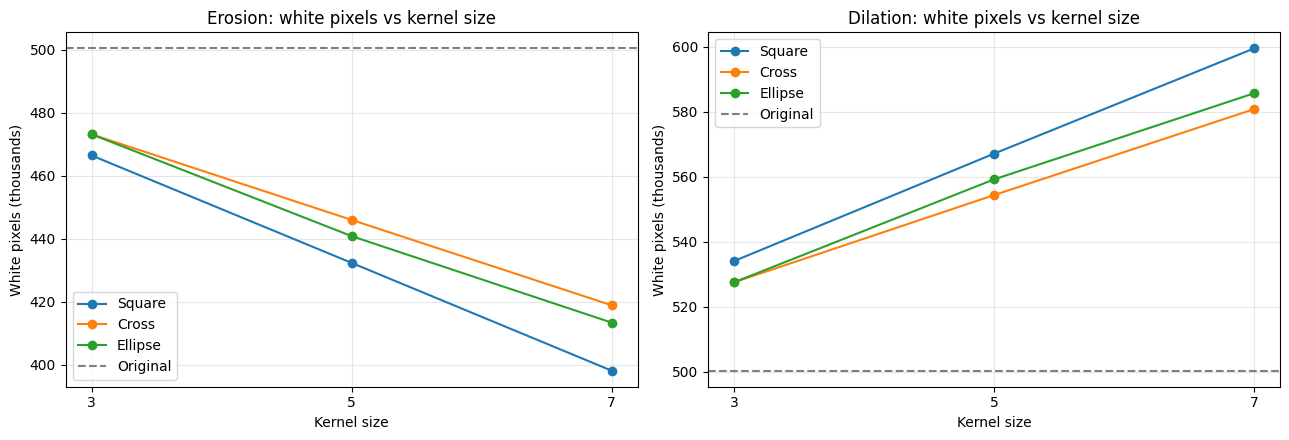

In [6]:
base = np.count_nonzero(binary)
print(f"Original: {base:,} white pixels, {n_components(binary)} objects\n")

for op_name, op in [('EROSION', erode_fn), ('DILATION', dilate_fn)]:
    print(f"=== {op_name} ===")
    print(f"{'Shape':10s}{'Size':>6s}{'White pixels':>15s}{'Change':>10s}{'Objects':>9s}")
    for sname, s in shapes.items():
        for k in sizes:
            out = op(binary, cv2.getStructuringElement(s, (k, k)))
            n = np.count_nonzero(out)
            print(f"{sname:10s}{str(k)+'x'+str(k):>6s}{n:15,d}{(n - base) / base * 100:9.1f}%{n_components(out):9d}")
    print()

# Plot the change in white pixels
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (op_name, op) in zip(axs, [('Erosion', erode_fn), ('Dilation', dilate_fn)]):
    for sname, s in shapes.items():
        vals = [np.count_nonzero(op(binary, cv2.getStructuringElement(s, (k, k)))) / 1e3 for k in sizes]
        ax.plot(sizes, vals, marker='o', label=sname)
    ax.axhline(base / 1e3, color='gray', ls='--', label='Original')
    ax.set_title(f'{op_name}: white pixels vs kernel size'), ax.set_xlabel('Kernel size'), ax.set_ylabel('White pixels (thousands)')
    ax.set_xticks(sizes), ax.legend(), ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observations (Task 2)

**Effect of kernel size**
* The bigger the kernel, the stronger the effect. Erosion removes more foreground pixels (rings get thinner, digit strokes shrink and eventually disappear), and dilation adds more pixels (rings get thicker, white number discs shrink, digits become blobs).
* The change grows roughly in proportion to the kernel size: a 3x3 kernel changes the boundary by 1 pixel, a 5x5 by 2 pixels and a 7x7 by 3 pixels on each side.

**Effect of kernel shape**
* Note: at 3x3 the cross and the ellipse are the same kernel, so they give identical results (527,560 / 473,108 pixels); they start to differ from 5x5 on.
* **Square** gives the strongest effect (it reaches the corners), and treats diagonal and straight edges differently: diagonal edges move by more than horizontal/vertical ones, which makes circles look slightly squarish.
* **Cross** gives the weakest effect: it only looks along the horizontal and vertical directions, so it removes/adds the fewest pixels and preserves diagonal parts and thin diagonal strokes of the digits better.
* **Ellipse (disc)** is in between and the most **isotropic**: it changes the boundary by the same amount in every direction, so the round balls stay round. It is the best choice for circular objects like these balls.

**Conclusion:** the kernel size controls *how much* the objects change, and the kernel shape controls *how* (in which directions) they change. Erosion and dilation are duals: erosion shrinks the white objects (and enlarges the holes inside them), dilation grows them (and shrinks the holes).